# Diabetes Type 2 Prediction

## Using datasets without Diet Score and Physical Activity

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

In [2]:
# Load the dataset
df = pd.read_csv("SukaaliCheckDataset2.csv")

print(df.shape)
print(df.info())
print(df['risk_level'].value_counts())

(1435, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1435 entries, 0 to 1434
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      1435 non-null   int64  
 1   sex                      1435 non-null   object 
 2   bmi                      1435 non-null   float64
 3   family_history_diabetes  1435 non-null   object 
 4   hypertension             1435 non-null   object 
 5   blood_glucose            1435 non-null   float64
 6   risk_level               1435 non-null   object 
dtypes: float64(2), int64(1), object(4)
memory usage: 78.6+ KB
None
risk_level
intermediate    674
low             403
high            358
Name: count, dtype: int64


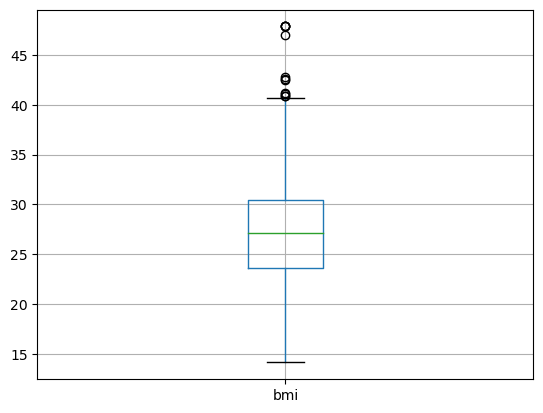

In [3]:
#OUTLIERS: These seem few
df.boxplot(column='bmi')
plt.show()

In [4]:
df = df[df['bmi'].between(13, 45)]
df.shape

(1430, 7)

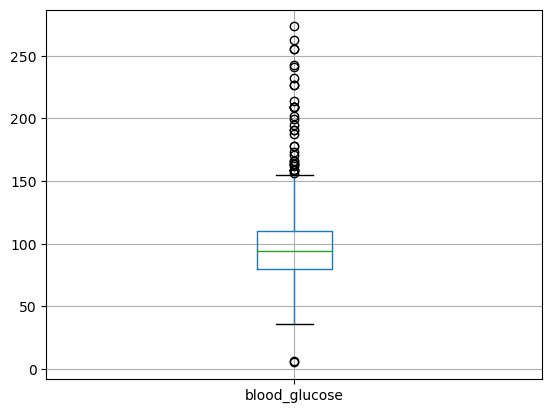

In [5]:
#OUTLIERS: These seem few
df.boxplot(column='blood_glucose')
plt.show()

In [6]:
df = df[df['blood_glucose'].between(30, 200)]
df.shape

(1413, 7)

In [7]:
# Convert categorical columns for Model Training
df_encoded = df.copy()
df_encoded['family_history_diabetes'] = df_encoded['family_history_diabetes'].map({"no": 0, "yes": 1})
df_encoded['hypertension'] = df_encoded['hypertension'].map({"no": 0, "yes": 1})
df_encoded['sex'] = df_encoded['sex'].map({"Male": 1, "Female": 0})
df_encoded['risk_level'] = df_encoded['risk_level'].map({"low": 0, "intermediate": 1, "high": 2})
print(df_encoded.head())
print(df_encoded.shape)
# Encoded file saved as CSV
df_encoded.to_csv("Dataset_Encoded.csv", index=False)

   age  sex    bmi  family_history_diabetes  hypertension  blood_glucose  \
0   28    1  23.20                        1             0           77.4   
1   38    1  29.34                        1             0           77.4   
2   23    0  22.04                        0             0          108.0   
3   26    1  17.67                        0             0          106.2   
4   33    0  21.66                        0             1          100.8   

   risk_level  
0           1  
1           0  
2           1  
3           1  
4           1  
(1413, 7)


In [8]:
# Preparing Data for Machine Learning

y = df_encoded['risk_level']
print(y.head())

X = df_encoded.drop('risk_level', axis = 1)
print(X.shape)

# Train/test split
X_train, X_temp, y_train, y_temp= train_test_split(X, y, test_size=0.3, random_state=123)

0    1
1    0
2    1
3    1
4    1
Name: risk_level, dtype: int64
(1413, 6)


In [9]:
# Split data for validation and testing
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=123)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (989, 6)
Validation: (212, 6)
Testing: (212, 6)


In [10]:
# Training a RandomForest Machine Learning Model

RFmodel = RandomForestClassifier(
    n_estimators=200,
    random_state=123
)

RFmodel.fit(X_train, y_train)

y_val_pred_before = RFmodel.predict(X_val)

print("\n*** BASELINE MODEL ***")
print(classification_report(y_val, y_val_pred_before))


*** BASELINE MODEL ***
              precision    recall  f1-score   support

           0       0.83      0.81      0.82        54
           1       0.81      0.81      0.81        98
           2       0.84      0.85      0.84        60

    accuracy                           0.82       212
   macro avg       0.82      0.82      0.82       212
weighted avg       0.82      0.82      0.82       212



In [11]:
# HYPERPARAMETER TUNING/ OPTIMIZATION
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=123),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

print("\nBest Parameters")
print(grid_search.best_params_)

print("\nBest Cross Validation Accuracy")
print(grid_search.best_score_)


best_model = grid_search.best_estimator_

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.5s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   1.1s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=   1.4s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=   2.4s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=300; total time=   2.1s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2, n_estimators=300; total time=   1.4s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split

[CV] END max_depth=10, max_features=log2, min_samples_leaf=4, min_samples_split=2, n_estimators=300; total time=   1.2s[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   1.2s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=   2.1s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=   1.7s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=200; total time=   1.3s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=300; total time=   1.7s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2, n_estimators=300; total time=   1.4s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=200; total time=   0.9s
[CV] END max_depth=None, 

[CV] END max_depth=10, max_features=log2, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time=   0.4s[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.6s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=   2.2s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=   2.2s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=200; total time=   1.9s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2, n_estimators=100; total time=   0.7s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2, n_estimators=200; total time=   0.9s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time=   0.4s
[CV] END max_depth=None, 

[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.5s[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.6s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=   1.8s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=   1.8s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=200; total time=   1.3s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=300; total time=   2.0s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2, n_estimators=300; total time=   1.4s
[CV] END max_depth=None,

[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.5s[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   1.1s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=   1.9s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=   2.0s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=300; total time=   2.3s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2, n_estimators=200; total time=   1.0s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2, n_estimators=300; total time=   1.4s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=300; total time=   1.3s
[CV] END max_depth=None, m

[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   0.4s[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.5s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   1.1s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   0.6s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=   1.4s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   0.6s
[CV] END max_depth=None, 

[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=   1.0s[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.6s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=   1.7s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=   1.4s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=   1.7s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=300; total time=   2.0s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2, n_estimators=200; total time=   1.0s
[CV] END max_depth=None, max_features=sqrt, min_samples_leaf=2, min_samples_split=2, n_estimators=300; total time=   1.5s
[CV] END max_depth=None, m

[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=   1.5s
[CV] END max_depth=10, max_features=log2, min_samples_leaf=4, min_samples_split=5, n_estimators=300; total time=   1.4s
[CV] END max_depth=10, max_features=log2, min_samples_leaf=4, min_samples_split=10, n_estimators=200; total time=   1.1s
[CV] END max_depth=10, max_features=log2, min_samples_leaf=4, min_samples_split=10, n_estimators=300; total time=   1.5s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=   1.5s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=   0.9s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   0.4s
[CV] END max_depth=20, max_features=

[CV] END max_depth=30, max_features=log2, min_samples_leaf=4, min_samples_split=5, n_estimators=100; total time=   0.4s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=   0.9s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   0.6s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=200; total time=   0.9s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=1, min_samples_split=10, n_estimators=300; total time=   1.5s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=2, min_samples_split=2, n_estimators=300; total time=   1.3s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=200; total time=   0.9s
[CV] END max_depth=20, max_features=s

[CV] END max_depth=30, max_features=log2, min_samples_leaf=4, min_samples_split=5, n_estimators=300; total time=   1.5s
Best Parameters
{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}

Best Cross Validation Accuracy
0.8129569809772855


In [12]:
# MODEL EVALUATION ON VALIDATION DATA
y_val_pred_after = best_model.predict(X_val)

print("\n*** OPTIMIZED MODEL ***")
print(classification_report(y_val, y_val_pred_after))
# why is the difference so small? More research


*** OPTIMIZED MODEL ***
              precision    recall  f1-score   support

           0       0.83      0.80      0.81        54
           1       0.78      0.81      0.79        98
           2       0.83      0.82      0.82        60

    accuracy                           0.81       212
   macro avg       0.81      0.81      0.81       212
weighted avg       0.81      0.81      0.81       212



In [13]:
# COMPARING BE4 & AFTER OPTIMIZATION
y_val_prob_before = RFmodel.predict_proba(X_val)
y_val_prob_after = best_model.predict_proba(X_val)

comparison = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],

    "Baseline":[

        accuracy_score(y_val, y_val_pred_before),

        precision_score(
            y_val,
            y_val_pred_before,
            average="weighted"
        ),

        recall_score(
            y_val,
            y_val_pred_before,
            average="weighted"
        ),

        f1_score(
            y_val,
            y_val_pred_before,
            average="weighted"
        ),

        roc_auc_score(
            y_val,
            y_val_prob_before,
            multi_class="ovr",
            average="weighted"
        )
    ],

    "Optimized":[

        accuracy_score(y_val, y_val_pred_after),

        precision_score(
            y_val,
            y_val_pred_after,
            average="weighted"
        ),

        recall_score(
            y_val,
            y_val_pred_after,
            average="weighted"
        ),

        f1_score(
            y_val,
            y_val_pred_after,
            average="weighted"
        ),

        roc_auc_score(
            y_val,
            y_val_prob_after,
            multi_class="ovr",
            average="weighted"
        )
    ]
})

comparison["Improvement"] = (
    comparison["Optimized"] -
    comparison["Baseline"]
)

print("\n*** PERFORMANCE COMPARISON ***")
print(comparison.round(4))


y_test_pred = best_model.predict(X_test)

print("\n*** FINAL TEST PERFORMANCE ***")
print(classification_report(y_test, y_test_pred))


*** PERFORMANCE COMPARISON ***
      Metric  Baseline  Optimized  Improvement
0   Accuracy    0.8208     0.8066      -0.0142
1  Precision    0.8207     0.8073      -0.0135
2     Recall    0.8208     0.8066      -0.0142
3   F1 Score    0.8207     0.8068      -0.0140
4    ROC AUC    0.9349     0.9345      -0.0004

*** FINAL TEST PERFORMANCE ***
              precision    recall  f1-score   support

           0       0.89      0.83      0.86        66
           1       0.80      0.84      0.82        89
           2       0.88      0.86      0.87        57

    accuracy                           0.84       212
   macro avg       0.85      0.85      0.85       212
weighted avg       0.85      0.84      0.84       212



In [14]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


Confusion Matrix:
[[55 11  0]
 [ 7 75  7]
 [ 0  8 49]]


In [15]:
joblib.dump(best_model, 'SukaaliCheckV2.pkl')

['SukaaliCheckV2.pkl']

In [16]:
joblib.dump(X.columns.tolist(), "feature_columnsSC.pkl")

['feature_columnsSC.pkl']

In [21]:
# Prediction function TO TEST Original RF MODEL
loaded_model = joblib.load('SukaaliCheckV2.pkl')

input_data = (30,1,24.9,0,0,84.5)
data_as_numpy = np.asarray(input_data)
reshaped_data = data_as_numpy.reshape(1,-1)

prediction = loaded_model.predict(reshaped_data)
print(prediction)

if prediction == 0:
    print('Low Diabetes risk predicted')
elif prediction == 1:
    print('Intermediate Diabetes risk predicted')
else:
    print('High Diabetes risk predicted!')

[0]
Low Diabetes risk predicted


/usr/lib/python3/dist-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
